# Mekong Delta Hydraulic Analysis - Vinh Chau and Nha Mat
Field data of the June 2025 and June 2026 campaigns, collected by Dr. Hoang Tung Dao (data and data description provided by him; not collected by us).
This notebook reads the data, flags invalid records (no data are removed), and shows the tables used in the report as notebook output:
- campaign conditions per year (offshore + nearshore)
- wave buoy statistics in the same format as the ERA5 overview
- tide/inundation and wave transformation offshore → nearshore
- appendix figures of all raw data per sensor

All times are local time (UTC+7). ERA5 is in UTC (shift −7 h when comparing).

# Setup of dataframe

In [ ]:
# import statements
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)   # pandas/numpy version mismatch, harmless


figures = {}
tables = {}

In [37]:
def read_data(file_path):

    df = pd.read_csv(file_path, sep="\t", comment="#")

    date_col = [col for col in df.columns if col.lower() == "date_time"][0]
    df = df.rename(columns={date_col: "Date_time"})

    df["Date_time"] = pd.to_datetime(
        df["Date_time"],
        format="%d/%m/%Y %H:%M"
    )

    for col in df.columns[1:]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

In [38]:
#collect data from from files

SAVE = False   # True = save figures and tables in results/ (overwrites the files there)

data_dir = Path('../data')
year_folder = {2025: data_dir / 'june2025', 2026: data_dir / 'june2026'}
fig_dir = Path('../results/june2025_2026')
table_dir = Path('../results/june2025_2026')

files = {
    2025: {
        "ssc_nearshore": "2025_Data_SSC_Nearshore.txt",
        "ssc_offshore": "2025_Data_SSC_Offshore.txt",
        "water_depth": "2025_Data_WaterDepth.txt",
        "adcp_flow": "2025_Data_Wave_ADCP_TXVC13_Flow.txt",
        "adcp_wave": "2025_Data_Wave_ADCP_TXVC13_Wave.txt",
        "twr_wave": "2025_Data_Wave_TWR2050R.txt",
        "buoy_wave": "2025_Data_Wave_WB2026.txt"
    },

    2026: {
        "water_depth": "2026_Data_WaterDepth.txt",
        "twr_wave": "2026_Data_Wave_TWR2050R.txt",
        "buoy_wave": "2026_Data_Wave_WB2026.txt"
    }
}

data = {
    year: {
        name: read_data(year_folder[year] / filename)
        for name, filename in datasets.items()
    }
    for year, datasets in files.items()
}

In [39]:
#check if dataframes are loaded correctly and their shapes
for year in data:

    print(f"\n{year}")

    for name, df in data[year].items():

        print(name, df.shape)


2025
ssc_nearshore (36, 2)
ssc_offshore (47, 2)
water_depth (297, 2)
adcp_flow (165, 3)
adcp_wave (165, 8)
twr_wave (128, 6)
buoy_wave (327, 5)

2026
water_depth (1152, 2)
twr_wave (1152, 6)
buoy_wave (324, 5)


# Table of RAW data provided

In [40]:
def data_summary(data):

    summary = []

    for year, datasets in data.items():
        for name, df in datasets.items():

            for col in df.columns:

                if col == "Date_time":
                    continue

                values = pd.to_numeric(df[col], errors="coerce")

                summary.append({
                    "Year": year,
                    "Dataset": name,
                    "Variable": col,
                    "N": values.count(),
                    "Missing": values.isna().sum(),
                    "Min": values.min(),
                    "Max": values.max(),
                    "Range": values.max() - values.min(),
                    "Mean": values.mean(),
                    "Median": values.median()
                })

    return pd.DataFrame(summary)


raw_summary = data_summary(data)

display(raw_summary.round(3))

,Year,Dataset,Variable,N,Missing,Min,Max,Range,Mean,Median
0,2025,ssc_nearshore,SSC_Near_g_lit,36,0,0.141,0.901,0.760,0.470,0.451
1,2025,ssc_offshore,SSC_Off_g_lit,47,0,0.111,0.886,0.775,0.264,0.208
2,2025,water_depth,water_depth_m,297,0,0.000,0.840,0.840,0.131,0.000
3,2025,adcp_flow,Vel,132,33,0.008,0.850,0.842,0.203,0.187
4,2025,adcp_flow,Dir,132,33,40.000,360.000,320.000,190.409,196.000
5,2025,adcp_wave,Depth,165,0,0.000,3.206,3.206,1.867,2.154
6,2025,adcp_wave,Hs,153,12,0.003,0.948,0.945,0.320,0.293
7,2025,adcp_wave,Tp,153,12,2.000,25.600,23.600,4.513,3.900
8,2025,adcp_wave,Direction,117,48,40.000,360.000,320.000,191.966,199.000
9,2025,adcp_wave,HsSwell,151,14,0.003,0.341,0.338,0.037,0.036


In [41]:
#data coverage summary from each device deployed, showing start and end data of data collection & number of measurements

coverage = []

for year, datasets in data.items():

    for name, df in datasets.items():

        coverage.append({
            "Year": year,
            "Dataset": name,
            "Start": df["Date_time"].min(),
            "End": df["Date_time"].max(),
            "N": len(df)
        })

coverage = pd.DataFrame(coverage)

display(coverage)

,Year,Dataset,Start,End,N
0,2025,ssc_nearshore,2025-06-12 09:00:00,2025-06-20 18:00:00,36
1,2025,ssc_offshore,2025-06-13 15:00:00,2025-06-20 06:00:00,47
2,2025,water_depth,2025-06-14 10:00:00,2025-06-20 14:00:00,297
3,2025,adcp_flow,2025-06-13 14:00:00,2025-06-20 10:00:00,165
4,2025,adcp_wave,2025-06-13 14:00:00,2025-06-20 10:00:00,165
5,2025,twr_wave,2025-06-12 12:00:00,2025-06-20 10:30:00,128
6,2025,buoy_wave,2025-06-13 14:00:00,2025-06-20 09:00:00,327
7,2026,water_depth,2026-06-22 18:00:00,2026-06-30 17:50:00,1152
8,2026,twr_wave,2026-06-22 18:00:00,2026-06-30 17:50:00,1152
9,2026,buoy_wave,2026-06-23 09:00:00,2026-06-30 09:00:00,324


In [42]:
for year, datasets in data.items():

    for name, df in datasets.items():

        measured_year = df["Date_time"].dt.year.mode()[0]

        assert measured_year == year, (
            f"{name}: expected {year}, "
            f"but data contains {measured_year}"
        )

In [43]:
#makes plot to show all data for the time series of a given variable in a given dataframe
def check_data(df, variable):

    print(df[variable].describe())

    plt.figure(figsize=(12, 4))
    plt.plot(df["Date_time"], df[variable])
    plt.ylabel(variable)
    plt.grid()
    plt.show()

#check_data(data[2025]["buoy_wave"], "Hs")
#check_data(data[2026]["buoy_wave"], "Hs")

# Processing of raw data

In [44]:
rename_columns = {
    "water_depth_m": "Depth",
    "Water_Depth_m": "Depth",
    "Significant wave height": "Hs",
    "Maximum wave height": "H_max",
    "Average wave height": "H_mean",
    "1/10 wave height": "H_10",
    "Wave energy": "Wave_energy",
    "SSC_Near_g_lit": "SSC",
    "SSC_Off_g_lit": "SSC"
}


stations = {
    2025: {
        "water_depth": "VC-NEAR",
        "twr_wave": "VC-NEAR",
        "ssc_nearshore": "VC-NEAR",
        "adcp_wave": "VC-OFF",
        "adcp_flow": "VC-OFF",
        "buoy_wave": "VC-OFF",
        "ssc_offshore": "VC-OFF"
    },

    2026: {
        "water_depth": "VC-TWR",
        "twr_wave": "VC-TWR",
        "buoy_wave": "VC-BUOY-S"
    }
}


processed = {}

for year, datasets in data.items():

    processed[year] = {}

    for name, df in datasets.items():

        df = df.rename(columns=rename_columns).copy()

        df["Station"] = stations[year][name]
        df["Campaign"] = year

        processed[year][name] = df

# Quality control
Records are flagged but not. Flagged records are left out of all statistics (see `drop_flagged` further down).
- Wave buoy: Tp = 18.2 s (lowest frequency bin) or unrealistic Hmax/Hs (< 1.3 or > 4)
- ADCP: < 0.35 m water above the sensor (data description) or failed spectrum (Tp > 10 s, Hs < 0.02 m); current gets the same flag
- TWR: periods when the logger was not in place (2025 placed 14/06 09:00; 2026 removed 29/06 17:10; handled 23/06 15:50–16:10)
- TWR depth: the logger reads an apparent depth at low tide → depth above its own low-tide reading (`h`); checked against the Diver (2025)
- Inundated: Diver depth > 0.02 m; TWR Hs ≥ 0.01 m
- 2026 buoy direction is the direction of travel → converted to direction of origin (`Dir_from`). From 34° there is only 14.5 km of open water, too short for the measured Tp (3–7 s).

In [45]:
# Quality control – functions

def flag_times(df, start=None, end=None, times=()):
    # True = record outside the deployment period or at a known bad time (rows are kept)
    flag = pd.Series(False, index=df.index)
    if start is not None:
        flag |= df["Date_time"] < pd.Timestamp(start)
    if end is not None:
        flag |= df["Date_time"] > pd.Timestamp(end)
    flag |= df["Date_time"].isin(pd.to_datetime(list(times)))
    return flag

def flag_buoy_artifacts(df, tp_bad=18.2, ratio_min=1.3, ratio_max=4.0):
    # Tp = 18.204 s spikes (lowest frequency bin), and unrealistic Hmax/Hs:
    # < 1.3 (incl. Hs > Hmax; normal 30-min records give ~1.4-2.2) or > 4
    ratio = df["H_max"] / df["Hs"]
    return (
        (df["Tp"].round(1) == tp_bad)
        | (ratio < ratio_min)
        | (ratio > ratio_max)
    )

def flag_adcp_invalid(df, min_depth=0.35, max_tp=10.0, min_hs=0.02):
    # too shallow above transducer, or failed spectrum (Tp 11.6/18.3/25.6 s, Hs ~0)
    return (
        (df["Depth"] < min_depth)
        | (df["Tp"] > max_tp)
        | (df["Hs"] < min_hs)
        | df["Hs"].isna()
    )

def remove_lowtide_baseline(df, dry, depth_col="Depth"):
    # depth above the logger's own low-tide reading, interpolated between neighbouring low tides
    # (TWR reads 0.1-0.2 m (2025) and ~1.2 m (2026) at low tide while there are no waves)
    base = pd.Series(df[depth_col].where(dry).to_numpy(), index=df["Date_time"])
    base = base.interpolate(method="time", limit_direction="both").to_numpy()
    return df[depth_col] - base

def direction_from(direction, convention):
    # nautical "coming from" direction; convention of the file: "from" (as is) or "to" (+180°)
    return direction % 360 if convention == "from" else (direction + 180) % 360

In [46]:
# Quality control – settings and flags (records are flagged, never removed)
twr2025_start = "2025-06-14 09:00"     # TWR not yet placed before this (no tidal signal; Diver starts 14/06 10:00)
twr2026_end   = "2026-06-29 17:00"     # TWR removed after this (flat ~0.84 m, no tide)
twr2026_drop  = ["2026-06-23 15:50", "2026-06-23 16:00", "2026-06-23 16:10"]   # logger handled (spike)
diver_wet     = 0.02                   # [m] Diver depth above this = inundated
twr_wet_hs    = 0.01                   # [m] TWR Hs above this = connected to the sea
buoy_dir_convention = {2025: "from", 2026: "to"}   # direction convention in the data files

# deployment periods
processed[2025]["twr_wave"]["QA_invalid"] = flag_times(processed[2025]["twr_wave"], start=twr2025_start)
for name in ["water_depth", "twr_wave"]:
    processed[2026][name]["QA_invalid"] = flag_times(processed[2026][name], end=twr2026_end, times=twr2026_drop)

# dry / inundated
processed[2025]["water_depth"]["exposed"] = processed[2025]["water_depth"]["Depth"] <= diver_wet
processed[2025]["twr_wave"]["dry_or_exposed"] = processed[2025]["twr_wave"]["Hs"] < twr_wet_hs
processed[2026]["twr_wave"]["dry_or_exposed"] = processed[2026]["twr_wave"]["Hs"] < twr_wet_hs

# wave buoy: artefacts and direction of origin (raw Dir kept)
for year in [2025, 2026]:
    processed[year]["buoy_wave"]["QA_outlier"] = flag_buoy_artifacts(processed[year]["buoy_wave"])
    processed[year]["buoy_wave"]["Dir_from"] = direction_from(processed[year]["buoy_wave"]["Dir"], buoy_dir_convention[year])

# ADCP: invalid wave records; current gets the same flag (same timestamps)
processed[2025]["adcp_wave"]["QA_invalid"] = flag_adcp_invalid(processed[2025]["adcp_wave"])
processed[2025]["adcp_flow"] = processed[2025]["adcp_flow"].merge(
    processed[2025]["adcp_wave"][["Date_time", "QA_invalid"]], on="Date_time", how="left"
)

# TWR 2025: depth above the logger's low-tide reading (2026: after merging depth and waves, see merge cell)
processed[2025]["twr_wave"]["h"] = remove_lowtide_baseline(
    processed[2025]["twr_wave"],
    processed[2025]["twr_wave"]["dry_or_exposed"] & ~processed[2025]["twr_wave"]["QA_invalid"]
)

print({y: int(processed[y]["buoy_wave"]["QA_outlier"].sum()) for y in [2025, 2026]}, "buoy records flagged")
print(int(processed[2025]["adcp_wave"]["QA_invalid"].sum()), "ADCP records flagged")

{2025: 8, 2026: 5} buoy records flagged
31 ADCP records flagged


# Wave calculations
p = 1025 kg/m3 --> seawater density,
E = pgHs2/16 --> standard wave-energy estimate

In [47]:
g = 9.81
rho = 1025

#dispersion relation for linear waves, used to calculate wave number from wave period and water depth. The function uses the Newton-Raphson method to iteratively solve for the wave number k given the wave period T and water depth h. The function returns NaN if T or h are NaN or non-positive.
def wave_number(T, h):

    if pd.isna(T) or pd.isna(h) or T <= 0 or h <= 0:
        return np.nan

    omega = 2*np.pi / T
    k = omega**2 / g

    for _ in range(50):
        kh = k*h
        f = g*k*np.tanh(kh) - omega**2
        df = g*(np.tanh(kh) + kh/np.cosh(kh)**2)

        k_new = k - f/df

        if abs(k_new - k) < 1e-10:
            break

        k = k_new

    return k


# function to add wave parameters to a dataframe containing wave data. The function calculates wave number, wavelength, wave regime, phase speed, group speed, wave energy, wave power, steepness, and bed orbital velocity based on the input dataframe and specified depth column. The function returns a new dataframe with the added parameters.
def add_wave_parameters(df, depth_col="Depth"):

    df = df.copy()

    df["k"] = [
        wave_number(T, h)
        for T, h in zip(df["Tp"], df[depth_col])
    ]

    df["L"] = 2*np.pi / df["k"]
    df["kh"] = df["k"] * df[depth_col]
    df["h_L"] = df[depth_col] / df["L"]

    df["wave_regime"] = pd.cut(
        df["h_L"],
        [-np.inf, 1/20, 1/2, np.inf],
        labels=["shallow", "intermediate", "deep"]
    )

    omega = 2*np.pi / df["Tp"]

    df["C"] = omega / df["k"]
    df["n"] = 0.5 * (1 + 2*df["kh"]/np.sinh(2*df["kh"]))
    df["Cg"] = df["n"] * df["C"]

    df["E"] = rho*g*df["Hs"]**2 / 16
    df["P"] = df["E"] * df["Cg"]

    df["steepness"] = df["Hs"] / df["L"]
    df["Hs_h"] = df["Hs"] / df[depth_col]

    df["U_bed"] = (
        np.pi*df["Hs"]
        / (df["Tp"] * np.sinh(df["kh"]))
    )

    return df

In [48]:
# Add wave parameters to 2025 TWr and ADCP wave data, which already have Hs, Tp and Depth. 

processed[2025]["twr_wave"] = add_wave_parameters(
    processed[2025]["twr_wave"], depth_col="h"
)

processed[2025]["adcp_wave"] = add_wave_parameters(
    processed[2025]["adcp_wave"]
)

2026 wave calculations cannot currently use the dispersion relation:

VC-TWR:
- Water depth and wave heights are available, but Tp is not provided.
- Without wave period, omega and therefore k cannot be calculated.

VC-BUOY-S:
- Hs and Tp are available, but no local water depth is provided.
- VC-TWR depth should NOT be used because VC-TWR and VC-BUOY-S are different locations.

The 2025 buoy has no depth of its own either; its wave parameters are not calculated (the ADCP depth goes to ~0 at low tide while the buoy still measures waves).

Therefore dispersion-based wavelength, C, Cg and wave power are not calculated for the 2026 datasets unless additional Tp or local depth data becomes available.

In [49]:
wave_data = {
    "VC-NEAR TWR": processed[2025]["twr_wave"].loc[
        ~processed[2025]["twr_wave"]["dry_or_exposed"] & ~processed[2025]["twr_wave"]["QA_invalid"]
    ],

    "VC-OFF ADCP": processed[2025]["adcp_wave"].loc[
        ~processed[2025]["adcp_wave"]["QA_invalid"]
    ]
}

summary = []

for name, df in wave_data.items():

    summary.append({
        "Dataset": name,
        "Hs_mean": df["Hs"].mean(),
        "Hs_max": df["Hs"].max(),
        "Tp_mean": df["Tp"].mean(),
        "Depth_mean": df["Depth"].mean(),
        "L_mean": df["L"].mean(),
        "Cg_mean": df["Cg"].mean(),
        "P_mean": df["P"].mean(),
        "U_bed_mean": df["U_bed"].mean()
    })

wave_summary = pd.DataFrame(summary)

display(wave_summary.round(3))

,Dataset,Hs_mean,Hs_max,Tp_mean,Depth_mean,L_mean,Cg_mean,P_mean,U_bed_mean
0,VC-NEAR TWR,0.110,0.419,2.414,0.566,4.571,1.676,24.621,0.221
1,VC-OFF ADCP,0.339,0.948,3.841,2.212,15.576,3.206,283.830,0.293


In [50]:
for name, df in wave_data.items():

    print("\n", name)
    display(df["wave_regime"].value_counts())


 VC-NEAR TWR


wave_regime
intermediate    29
shallow          2
deep             0
Name: count, dtype: int64


 VC-OFF ADCP


wave_regime
intermediate    132
shallow           2
deep              0
Name: count, dtype: int64

None of the measurements collected fall within deep water regime. 

# Combine measured and calculated data

In [51]:
# Merging datasets based on which time stamp is nearest. The datasets are conducted in the same campaign, but have different timestamps because they have different measurement frequencies. This allows the data to be compared by matching nearest timestaps.
# The dataset with the least measurements is used as the backbone, and the other dataset is merged to it. The tolerance is set to 1 hour, meaning that if the nearest timestamp is more than 1 hour away, it will not be merged.
def merge_nearest(left, right, tolerance="1h"):

    return pd.merge_asof(                   
        left.sort_values("Date_time"),
        right.sort_values("Date_time"),
        on="Date_time",
        direction="nearest",
        tolerance=pd.Timedelta(tolerance)
    )

#nearshore 2025 data
ssc_near = processed[2025]["ssc_nearshore"][
    ["Date_time", "SSC"]
].copy()

twr_near = processed[2025]["twr_wave"][
    ["Date_time", "Depth", "Hs", "Tp",
     "U_bed", "P", "L", "Cg", "steepness", "Hs_h",
     "dry_or_exposed"]
].rename(columns={"Depth": "TWR_depth"})

water_near = processed[2025]["water_depth"][
    ["Date_time", "Depth"]
].rename(columns={"Depth": "Water_depth"})

near_2025_ssc = merge_nearest(ssc_near, twr_near)
near_2025_ssc = merge_nearest(near_2025_ssc, water_near)

#offshore 2025 data
adcp_wave = processed[2025]["adcp_wave"][
    ["Date_time", "Depth", "Hs", "Tp", "Direction",
     "HsSwell", "TpSwell", "DpSwell",
     "U_bed", "P", "L", "Cg", "steepness", "Hs_h"]
].rename(columns={"Direction": "Wave_direction"})

adcp_flow = processed[2025]["adcp_flow"][
    ["Date_time", "Vel", "Dir"]
].rename(columns={
    "Vel": "Current_velocity",
    "Dir": "Current_direction"
})

ssc_off = processed[2025]["ssc_offshore"][
    ["Date_time", "SSC"]
]

# ADCP wave and current data have the same hourly timestamps
off_2025 = pd.merge(
    adcp_wave,
    adcp_flow,
    on="Date_time",
    how="outer"
)

# ADCP measurements may be unreliable below ~0.35 m water depth, Tung instructions
off_2025["low_depth_flag"] = off_2025["Depth"] < 0.35

off_2025_ssc = merge_nearest(ssc_off, off_2025)

# VC-TWR 2026 data
#2026 VC-TWR data, water depth and wave data both every 10 minutes, can be joined directly
near_2026 = pd.merge(
    processed[2026]["water_depth"][["Date_time", "Depth"]],
    processed[2026]["twr_wave"],
    on="Date_time",
    how="inner"
)
near_2026["h"] = remove_lowtide_baseline(near_2026, near_2026["dry_or_exposed"] & ~near_2026["QA_invalid"])

In [52]:

# Nearshore: exclude dry/exposed TWR measurements
near_ssc_valid = near_2025_ssc.loc[
    (near_2025_ssc["dry_or_exposed"] == False)
    & (near_2025_ssc["Water_depth"] > 0)
].copy()

# Offshore: exclude ADCP measurements below reliable depth
off_ssc_valid = off_2025_ssc.loc[
    off_2025_ssc["Depth"] >= 0.35
].copy()

# Offshore hydrodynamic data
off_2025_valid = off_2025.loc[
    off_2025["Depth"] >= 0.35
].copy()

# Campaign tables 
Outliers are removed first, then:
- conditions per campaign: one offshore and one nearshore row (means, as in the ERA5 overview)
- wave buoy statistics in the ERA5 format
The tables are shown as output below each cell.

In [53]:

def drop_flagged(df, flag_cols):
    # copy of df without the records flagged in any of flag_cols (processed data stay complete)
    keep = pd.Series(True, index=df.index)
    for c in flag_cols:
        keep &= ~df[c].fillna(False).astype(bool)
    return df.loc[keep].copy()

def high_waters(df, depth_col="Depth", min_sep_h=8, prominence=0.2):
    # one value per tidal high water (peaks at least min_sep_h apart)
    s = df.dropna(subset=[depth_col]).sort_values("Date_time")
    dt_h = s["Date_time"].diff().dt.total_seconds().median() / 3600
    idx, _ = find_peaks(s[depth_col].to_numpy(), distance=max(1, int(min_sep_h / dt_h)), prominence=prominence)
    return s.iloc[idx][["Date_time", depth_col]]

def hw_stat(df, depth_col="Depth", prominence=0.2):
    hw = high_waters(df, depth_col, prominence=prominence)[depth_col]
    return f"{hw.median():.2f} ({hw.min():.2f}–{hw.max():.2f}), n={len(hw)}"

def med_p10_p90(x, decimals=2):
    x = pd.Series(x).dropna()
    if len(x) == 0:
        return "—"
    f = f"{{:.{decimals}f}}"
    return f"{f.format(x.median())} ({f.format(x.quantile(0.1))}–{f.format(x.quantile(0.9))})"

def circ_median_deg(x):
    r = np.deg2rad(pd.Series(x).dropna())
    return np.rad2deg(np.arctan2(np.sin(r).median(), np.cos(r).median())) % 360

def circ_mean_deg(x):
    r = np.deg2rad(pd.Series(x).dropna())
    return np.rad2deg(np.arctan2(np.sin(r).mean(), np.cos(r).mean())) % 360

def record_period(df):
    return f"{df['Date_time'].min():%d/%m %H:%M} – {df['Date_time'].max():%d/%m %H:%M}"

def conditions_row(waves=None, dir_col="Dir_from", current=None, hw=None, inundated=None, hs_h=None,
                   not_measured=()):
    row = dict.fromkeys(COND_COLS, "–")
    if waves is not None:
        row["Hs (m)"] = f"{waves['Hs'].mean():.2f}"
        row["Hs 95th (m)"] = f"{waves['Hs'].quantile(0.95):.2f}"
        if "Tp" in waves:
            row["Tp (s)"] = f"{waves['Tp'].mean():.1f}"
        if dir_col in waves:
            row["Wave dir. (°)"] = f"{circ_mean_deg(waves[dir_col]):.0f}"
    if current is not None:
        row["Current (m/s)"] = f"{pd.Series(current).mean():.2f}"
    if hw is not None:
        row["High-water depth (m)"] = f"{pd.Series(hw).mean():.2f}"
    if inundated is not None:
        row["Inundated (%)"] = f"{inundated:.0f}"
    if hs_h is not None:
        row["Hs/h (–)"] = f"{pd.Series(hs_h).mean():.2f}"
    for c in not_measured:
        row[c] = "not measured"
    return row

def wave_summary(df, hs="Hs", tp="Tp", direction="Dir_from", q=0.95):
    return {"Hs (m)": df[hs].mean(), f"Hs {int(q*100)}th (m)": df[hs].quantile(q),
            "Tp (s)": df[tp].mean(), "Wave dir. (°)": circ_mean_deg(df[direction])}

def peak_event(df, threshold, hs="Hs", tp="Tp", direction="Dir_from"):
    df = df.sort_values("Date_time").reset_index(drop=True)
    i = df[hs].idxmax()
    above = df[hs] >= threshold
    start, end = i, i
    while start > 0 and above[start - 1]:
        start -= 1
    while end < len(df) - 1 and above[end + 1]:
        end += 1
    dt = pd.Timedelta(df["Date_time"].diff().median())
    duration_h = (df.loc[end, "Date_time"] - df.loc[start, "Date_time"] + dt) / pd.Timedelta("1h")
    row = {"Hs (m)": df.loc[i, hs], "Hs 95th (m)": np.nan, "Tp (s)": df.loc[i, tp],
           "Wave dir. (°)": df.loc[i, direction]}
    return row, df.loc[i, "Date_time"], duration_h

COND_COLS = ["Hs (m)", "Hs 95th (m)", "Tp (s)", "Wave dir. (°)", "Current (m/s)",
             "High-water depth (m)", "Inundated (%)", "Hs/h (–)"]

In [54]:
# Setting to remove outliers before statistics 

min_h_ratio = 0.2      # [m] Hs/h and wave transformation only where h >= this

outlier_flags = {
    "adcp_wave_2025": (processed[2025]["adcp_wave"], ["QA_invalid"]),
    "adcp_flow_2025": (processed[2025]["adcp_flow"], ["QA_invalid"]),
    "buoy_2025":      (processed[2025]["buoy_wave"], ["QA_outlier"]),
    "diver_2025":     (processed[2025]["water_depth"], []),
    "twr_2025":       (processed[2025]["twr_wave"], ["QA_invalid"]),
    "buoy_2026":      (processed[2026]["buoy_wave"], ["QA_outlier"]),
    "twr_2026":       (near_2026, ["QA_invalid"]),
}
clean = {name: drop_flagged(df, flags) for name, (df, flags) in outlier_flags.items()}

qa_summary = pd.DataFrame({
    "Records": {n: len(df) for n, (df, _) in outlier_flags.items()},
    "Removed": {n: len(df) - len(clean[n]) for n, (df, _) in outlier_flags.items()},
    "Used":    {n: len(clean[n]) for n in clean},
})
display(qa_summary)

# data sets used in the tables 
buoy25, buoy26 = clean["buoy_2025"], clean["buoy_2026"]
adcp25, flow25 = clean["adcp_wave_2025"], clean["adcp_flow_2025"]
diver25 = clean["diver_2025"]
twr25_wet = clean["twr_2025"].loc[~clean["twr_2025"]["dry_or_exposed"]]
twr26 = clean["twr_2026"]
twr26_wet = twr26.loc[~twr26["dry_or_exposed"]]
hs_h = lambda df: (df["Hs"] / df["h"]).where(df["h"] >= min_h_ratio)

,Records,Removed,Used
adcp_wave_2025,165,31,134
adcp_flow_2025,165,31,134
buoy_2025,327,8,319
diver_2025,297,0,297
twr_2025,128,30,98
buoy_2026,324,5,319
twr_2026,1152,152,1000


In [55]:
# Conditions tables per campaign: one offshore and one nearshore row – settings here
# 2025 offshore: waves from the buoy (whole tide), current + high-water depth from the ADCP
# 2025 nearshore: waves + Hs/h from the TWR, high-water depth + inundation from the Diver (continuous)
hw25 = high_waters(diver25, prominence=0.1)["Depth"]
hw25_adcp = high_waters(adcp25)["Depth"]
hw26 = high_waters(twr26, depth_col="h", prominence=0.1)["h"]

conditions_2025 = pd.DataFrame({
    "Offshore (VC-OFF)":   conditions_row(waves=buoy25, current=flow25["Vel"], hw=hw25_adcp),
    "Nearshore (VC-NEAR)": conditions_row(waves=twr25_wet, hw=hw25,
                                          inundated=100 * (diver25["Depth"] > diver_wet).mean(),
                                          hs_h=hs_h(twr25_wet)),
}).T

conditions_2026 = pd.DataFrame({
    "Offshore (VC-BUOY-S)": conditions_row(waves=buoy26, not_measured=["Current (m/s)"]),
    "Nearshore (VC-TWR)":   conditions_row(waves=twr26_wet[["Hs"]], hw=hw26,
                                           inundated=100 * (~twr26["dry_or_exposed"]).mean(),
                                           hs_h=hs_h(twr26_wet), not_measured=["Tp (s)", "Current (m/s)"]),
}).T

print("Conditions June 2025")
display(conditions_2025)
print("Conditions June 2026")
display(conditions_2026)
print(f"Means over outlier-free records; Hs 95th = 95th percentile. Nearshore waves only while inundated; "
      f"Hs/h only where h >= {min_h_ratio} m. High-water depth: mean of all tidal high waters.\n"
      f"2025: offshore high-water depth = depth above the ADCP sensor; inundated = Diver depth > {diver_wet} m.\n"
      f"2026: high-water depth = TWR depth above its low-tide reading; inundated = TWR Hs >= {twr_wet_hs} m; "
      "no currents measured, TWR gives no Tp; wave direction converted to direction of origin.")


Conditions June 2025


,Hs (m),Hs 95th (m),Tp (s),Wave dir. (°),Current (m/s),High-water depth (m),Inundated (%),Hs/h (–)
Offshore (VC-OFF),0.34,0.59,4.0,198,0.19,2.99,–,–
Nearshore (VC-NEAR),0.11,0.26,2.4,–,–,0.56,38,0.26


Conditions June 2026


,Hs (m),Hs 95th (m),Tp (s),Wave dir. (°),Current (m/s),High-water depth (m),Inundated (%),Hs/h (–)
Offshore (VC-BUOY-S),0.77,1.01,4.9,214,not measured,–,–,–
Nearshore (VC-TWR),0.15,0.31,not measured,–,not measured,0.69,48,0.31


Means over outlier-free records; Hs 95th = 95th percentile. Nearshore waves only while inundated; Hs/h only where h >= 0.2 m. High-water depth: mean of all tidal high waters.
2025: offshore high-water depth = depth above the ADCP sensor; inundated = Diver depth > 0.02 m.
2026: high-water depth = TWR depth above its low-tide reading; inundated = TWR Hs >= 0.01 m; no currents measured, TWR gives no Tp; wave direction converted to direction of origin.


In [56]:
# Campaign table in the same format as the ERA5 table – settings here
include_era5_reference = True
era5_sw_monsoon = {"Hs (m)": 0.637, "Hs 95th (m)": 0.983, "Tp (s)": 4.185, "Wave dir. (°)": 227.722}   # ERA5 Table 5.1

rows, peaks, peaks_info = {}, {}, []
for label, df in {"June 2025 (VC-OFF)": clean["buoy_2025"], "June 2026 (VC-BUOY-S)": clean["buoy_2026"]}.items():
    rows[label] = wave_summary(df)
    row, t_peak, dur = peak_event(df, threshold=rows[label]["Hs 95th (m)"])
    peaks[f"Highest waves {label[5:9]}"] = row
    peaks_info.append(f"{t_peak:%d/%m %H:%M}, {dur:.1f} h above the campaign 95th percentile")
    print(f"{label}: peak Hs {row['Hs (m)']:.2f} m at {t_peak:%d/%m/%Y %H:%M} (UTC+7), "
          f"{dur:.1f} h above the campaign 95th percentile")

campaign_table = pd.DataFrame({**rows, **peaks}).T
if include_era5_reference:
    campaign_table.loc["ERA5 SW monsoon 2025 (reference)"] = era5_sw_monsoon

campaign_table_fmt = campaign_table.copy().astype(object)
for col, dec in {"Hs (m)": 2, "Hs 95th (m)": 2, "Tp (s)": 1, "Wave dir. (°)": 0}.items():
    campaign_table_fmt[col] = campaign_table[col].map(lambda v: "—" if pd.isna(v) else f"{v:.{dec}f}")
print("Wave buoy statistics (ERA5 format)")
display(campaign_table_fmt)
print("Highest waves: record with the highest Hs. Wave direction: direction of origin (2026 converted). "
      "ERA5 row: SW-monsoon values from Table 5.1 (offshore grid point, 2025).")


June 2025 (VC-OFF): peak Hs 0.76 m at 18/06/2025 11:00 (UTC+7), 2.5 h above the campaign 95th percentile
June 2026 (VC-BUOY-S): peak Hs 1.11 m at 25/06/2026 01:00 (UTC+7), 6.5 h above the campaign 95th percentile
Wave buoy statistics (ERA5 format)


,Hs (m),Hs 95th (m),Tp (s),Wave dir. (°)
June 2025 (VC-OFF),0.34,0.59,4.0,198
June 2026 (VC-BUOY-S),0.77,1.01,4.9,214
Highest waves 2025,0.76,—,3.5,146
Highest waves 2026,1.11,—,4.7,210
ERA5 SW monsoon 2025 (reference),0.64,0.98,4.2,228


Highest waves: record with the highest Hs. Wave direction: direction of origin (2026 converted). ERA5 row: SW-monsoon values from Table 5.1 (offshore grid point, 2025).


# Tide, inundation and wave transformation
- inundation, flood/ebb duration, high-water lag and depth difference VC-OFF → VC-NEAR (mudflat slope)
- wave transformation buoy → TWR: K, energy share K², fit Hs_near = min(a·Hs_off, γ·h), R², Pearson r

In [57]:
# Tide, inundation and wave transformation: functions
from scipy.optimize import curve_fit
import matplotlib.dates as mdates

C25, C26, C_GREY = "#2a78d6", "#eb6834", "#8a887f"


def refine_peaks(df, col, prominence):
    hw = high_waters(df, col, prominence=prominence)
    s = df.set_index("Date_time")[col].sort_index()
    out = []
    for t in hw["Date_time"]:
        i = s.index.get_loc(t)
        if 0 < i < len(s) - 1:
            y0, y1, y2 = s.iloc[i - 1], s.iloc[i], s.iloc[i + 1]
            den = y0 - 2 * y1 + y2
            shift = 0.5 * (y0 - y2) / den if den != 0 else 0.0
            out.append((t + shift * (s.index[i + 1] - s.index[i]), y1 - 0.25 * (y0 - y2) * shift))
    return pd.DataFrame(out, columns=["t", "hw"])


def flood_ebb_duration(df, col, hw_times, level=0.1, window_h=8):
    s = df.set_index("Date_time")[col].sort_index()
    out = []
    for t in hw_times:
        seg = s[(s.index >= t - pd.Timedelta(hours=window_h)) & (s.index <= t + pd.Timedelta(hours=window_h))]
        before, after = seg[seg.index <= t], seg[seg.index >= t]
        below_b, below_a = before[before < level], after[after < level]
        if len(below_b) == 0 or len(below_a) == 0:
            continue                       
        t0 = below_b.index[-1]; n0 = before.index[before.index.get_loc(t0) + 1]
        t1 = below_a.index[0];  p1 = after.index[after.index.get_loc(t1) - 1]
        t_rise = t0 + (n0 - t0) * ((level - before[t0]) / (before[n0] - before[t0]))
        t_fall = p1 + (t1 - p1) * ((after[p1] - level) / (after[p1] - after[t1]))
        out.append({"hw_time": t, "hw": s[t],
                    "flood_h": (t - t_rise) / pd.Timedelta("1h"), "ebb_h": (t_fall - t) / pd.Timedelta("1h")})
    return pd.DataFrame(out)


def exceedance(depth, levels):
    # % of time the water depth exceeds each level (dry records count as 0 m)
    depth = pd.Series(depth).fillna(0)
    return pd.Series({lv: 100 * (depth > lv).mean() for lv in levels})


def pair_waves(near, off, tolerance):
    # nearshore record matched to the nearest offshore buoy record
    n = near[["Date_time", "Hs", "h"]].rename(columns={"Hs": "Hs_near"})
    o = off[["Date_time", "Hs", "Tp"]].rename(columns={"Hs": "Hs_off", "Tp": "Tp_off"})
    p = pd.merge_asof(n.sort_values("Date_time"), o.sort_values("Date_time"), on="Date_time",
                      direction="nearest", tolerance=pd.Timedelta(tolerance)).dropna(subset=["Hs_off"])
    p["K"] = p["Hs_near"] / p["Hs_off"]          # transmission coefficient
    p["Hs_h"] = p["Hs_near"] / p["h"]
    return p


def fit_depth_limited(p):
    model = lambda X, a, g: np.minimum(a * X[0], g * X[1])
    X = (p["Hs_off"].to_numpy(), p["h"].to_numpy())
    (a, g), _ = curve_fit(model, X, p["Hs_near"].to_numpy(), p0=[0.5, 0.3])
    pred = model(X, a, g)
    r2 = 1 - ((p["Hs_near"] - pred) ** 2).sum() / ((p["Hs_near"] - p["Hs_near"].mean()) ** 2).sum()
    rmse = np.sqrt(((p["Hs_near"] - pred) ** 2).mean())
    limited = (g * X[1] < a * X[0]).mean() * 100     # % of records where depth limits the wave height
    return {"a": a, "gamma": g, "R2": r2, "RMSE": rmse, "depth_limited_pct": limited}


def style_axis(ax):
    ax.grid(axis="y", color="#e4e4e2", lw=0.6)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(labelsize=7)


def shade_wet(ax, t, wet, color="#e8f0fb"):
    t, wet = pd.Series(t).reset_index(drop=True), pd.Series(wet).reset_index(drop=True)
    groups = (wet != wet.shift()).cumsum()
    for _, g in t.groupby(groups):
        if wet[g.index[0]]:
            ax.axvspan(g.iloc[0], g.iloc[-1], color=color, lw=0, zorder=0)

In [58]:
# Tide, inundation and wave transformation: settings

flood_level = 0.1          # [m] level for flood/ebb duration (avoids the slow drainage tail)
exc_levels = [0.02, 0.1, 0.2, 0.3, 0.5, 0.7]

#tides and inundation 
depth25 = diver25.set_index("Date_time")["Depth"]                                 
depth26 = twr26.set_index("Date_time")["h"].where(~twr26.set_index("Date_time")["dry_or_exposed"], 0)  
hw_off25 = refine_peaks(processed[2025]["adcp_wave"], "Depth", 0.2)
hw_near25 = refine_peaks(diver25, "Depth", 0.1)
hw_near26 = refine_peaks(twr26, "h", 0.1)

fe25 = flood_ebb_duration(diver25, "Depth", high_waters(diver25, prominence=0.1)["Date_time"], flood_level)
fe26 = flood_ebb_duration(twr26, "h", high_waters(twr26, depth_col="h", prominence=0.1)["Date_time"], flood_level)
fe25, fe26 = fe25[fe25["hw"] >= 0.2], fe26[fe26["hw"] >= 0.2]

exc = pd.DataFrame({"June 2025 (VC-NEAR)": exceedance(depth25, exc_levels),
                    "June 2026 (VC-TWR)": exceedance(depth26, exc_levels)})

# offshore to nearshore high water (2025): time lag and depth difference -> mudflat slope
hw_pair = pd.merge_asof(hw_near25.sort_values("t"), hw_off25.rename(columns={"t": "t_off", "hw": "hw_off"}).sort_values("t_off"),
                        left_on="t", right_on="t_off", direction="nearest", tolerance=pd.Timedelta("1h")).dropna()
hw_pair = hw_pair[hw_pair["hw"] >= 0.3]                     
hw_pair["lag_min"] = (hw_pair["t"] - hw_pair["t_off"]) / pd.Timedelta("1min")
hw_pair["depth_diff"] = hw_pair["hw_off"] - hw_pair["hw"]
cross_shore_km = 2.39                                       
adcp_height = [0.0, 0.5]                                    
slope = [cross_shore_km * 1000 / (hw_pair["depth_diff"].median() + s) for s in adcp_height]  

tide_table = pd.DataFrame({
    "June 2025 (VC-NEAR)": {"High waters": len(hw_near25), "Inundated (%)": exc.iloc[0, 0],
                            "Wet hours per day (h)": exc.iloc[0, 0] * 0.24,
                            "Flood duration (h)": fe25["flood_h"].mean(), "Ebb duration (h)": fe25["ebb_h"].mean(),
                            "Depth > 0.3 m (%)": exc.loc[0.3].iloc[0]},
    "June 2026 (VC-TWR)": {"High waters": len(hw_near26), "Inundated (%)": exc.iloc[0, 1],
                           "Wet hours per day (h)": exc.iloc[0, 1] * 0.24,
                           "Flood duration (h)": fe26["flood_h"].mean(), "Ebb duration (h)": fe26["ebb_h"].mean(),
                           "Depth > 0.3 m (%)": exc.loc[0.3].iloc[1]},
}).T
print("Tide and inundation at the mudflat")
display(tide_table.round(1))
print(f"Flood shorter than ebb: 2025 {(fe25.flood_h < fe25.ebb_h).sum()}/{len(fe25)} tides, "
      f"2026 {(fe26.flood_h < fe26.ebb_h).sum()}/{len(fe26)} tides")
print(f"HW lag VC-NEAR after VC-OFF: median {hw_pair['lag_min'].median():.0f} min (n = {len(hw_pair)}); "
      f"depth difference at HW: median {hw_pair['depth_diff'].median():.2f} m "
      f"(IQR {hw_pair['depth_diff'].quantile(.25):.2f}–{hw_pair['depth_diff'].quantile(.75):.2f})")
print(f"Mudflat slope VC-OFF – VC-NEAR: 1:{slope[1]:.0f} to 1:{slope[0]:.0f}; "
      f"waterline shift per 0.1 m water level: {slope[1]*0.1:.0f}–{slope[0]*0.1:.0f} m")

# wave transformation
pairs = {"June 2025": pair_waves(twr25_wet[twr25_wet["h"] >= min_h_ratio], buoy25, "30min"),
         "June 2026": pair_waves(twr26_wet[twr26_wet["h"] >= min_h_ratio], buoy26, "15min")}
fits = {k: fit_depth_limited(p) for k, p in pairs.items()}

transfo_table = pd.DataFrame({k: {"n": len(p), "Hs offshore (m)": p["Hs_off"].mean(), "Hs nearshore (m)": p["Hs_near"].mean(),
                                  "K = Hs_near/Hs_off (–)": p["K"].mean(), "Energy reaching nearshore (%)": 100 * (p["K"] ** 2).mean(),
                                  "gamma (–)": fits[k]["gamma"], "a (–)": fits[k]["a"],
                                  "Depth-limited (%)": fits[k]["depth_limited_pct"], "R2 (–)": fits[k]["R2"],
                                  "RMSE (m)": fits[k]["RMSE"],
                                  "r Hs_off (–)": p["Hs_near"].corr(p["Hs_off"]), "r h (–)": p["Hs_near"].corr(p["h"])}
                              for k, p in pairs.items()}).T
transfo_table.loc[transfo_table["Depth-limited (%)"] >= 100, "a (–)"] = np.nan   
print("Wave transformation offshore -> nearshore (pairs with nearshore h >= 0.2 m)")
display(transfo_table.round(2))
tables["wave_transformation_2025_2026"] = transfo_table.round(2)
print("K = Hs_near/Hs_off; energy = mean of K². Fit: Hs_near = min(a·Hs_off, γ·h); R2 = variance explained by the fit; "
      "r = Pearson correlation of Hs_near with Hs_off and with h. a is empty when all records are depth-limited.")


Tide and inundation at the mudflat


,High waters,Inundated (%),Wet hours per day (h),Flood duration (h),Ebb duration (h),Depth > 0.3 m (%)
June 2025 (VC-NEAR),11.0,38.0,9.1,1.9,2.4,20.5
June 2026 (VC-TWR),13.0,47.8,11.5,2.3,2.6,32.1


Flood shorter than ebb: 2025 8/10 tides, 2026 5/6 tides
HW lag VC-NEAR after VC-OFF: median 0 min (n = 9); depth difference at HW: median 2.52 m (IQR 2.49–2.54)
Mudflat slope VC-OFF – VC-NEAR: 1:791 to 1:949; waterline shift per 0.1 m water level: 79–95 m
Wave transformation offshore -> nearshore (pairs with nearshore h >= 0.2 m)


/var/folders/1s/xn6lwjk12llbjb2b2763xk1m0000gn/T/ipykernel_92321/1897801432.py:60: OptimizeWarning: Covariance of the parameters could not be estimated
  (a, g), _ = curve_fit(model, X, p["Hs_near"].to_numpy(), p0=[0.5, 0.3])


,n,Hs offshore (m),Hs nearshore (m),K = Hs_near/Hs_off (–),Energy reaching nearshore (%),gamma (–),a (–),Depth-limited (%),R2 (–),RMSE (m),r Hs_off (–),r h (–)
June 2025,23.0,0.37,0.13,0.33,13.53,0.35,0.43,47.83,0.62,0.06,0.79,0.71
June 2026,364.0,0.79,0.18,0.23,6.80,0.32,NaN,100.00,0.88,0.03,-0.02,0.94


K = Hs_near/Hs_off; energy = mean of K². Fit: Hs_near = min(a·Hs_off, γ·h); R2 = variance explained by the fit; r = Pearson correlation of Hs_near with Hs_off and with h. a is empty when all records are depth-limited.


# SSC relationships
(Handled by a colleague – not changed here. Notes for the check: 8 of 25 nearshore samples were taken while the Diver site was dry; the offshore SSC–Tp correlation is driven by one sample at an ADCP artefact (20/06 00:00); the rising/falling classifier below labels dry and slack periods as "rising".)

In [59]:
# Are larger waves associated with higher SSC?
# Scc vs Hs, Tp, depth, and U_bed for nearshore and offshore, offshore also current velocity

def plot_ssc_relationships(df, variables, labels, location):

    fig, axes = plt.subplots(1, len(variables), figsize=(15, 4))

    for ax, variable, label in zip(axes, variables, labels):

        ax.scatter(df[variable], df["SSC"])
        ax.set_xlabel(label)
        ax.set_ylabel("SSC [g/L]")
        ax.set_title(f"{location}: SSC vs {label}")
        ax.grid()

    plt.tight_layout()
    figures[f"ssc_relationships_{location.lower()}"] = fig
    plt.show()


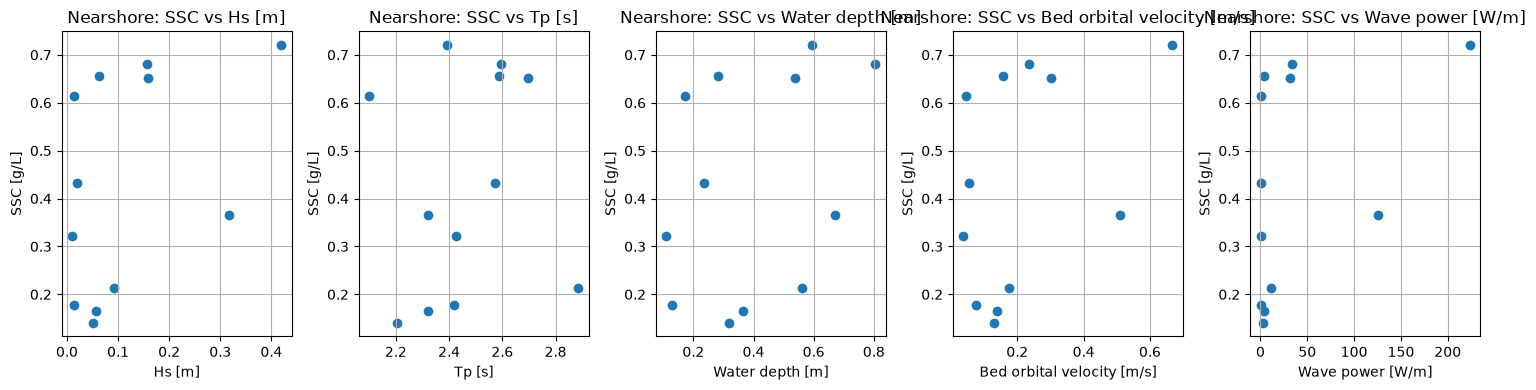

In [60]:
# Nearshore SSC relationships

plot_ssc_relationships(
    near_ssc_valid,
    ["Hs", "Tp", "Water_depth", "U_bed", "P"],
    ["Hs [m]",
     "Tp [s]",
     "Water depth [m]",
     "Bed orbital velocity [m/s]",
     "Wave power [W/m]"],
    "Nearshore"
)

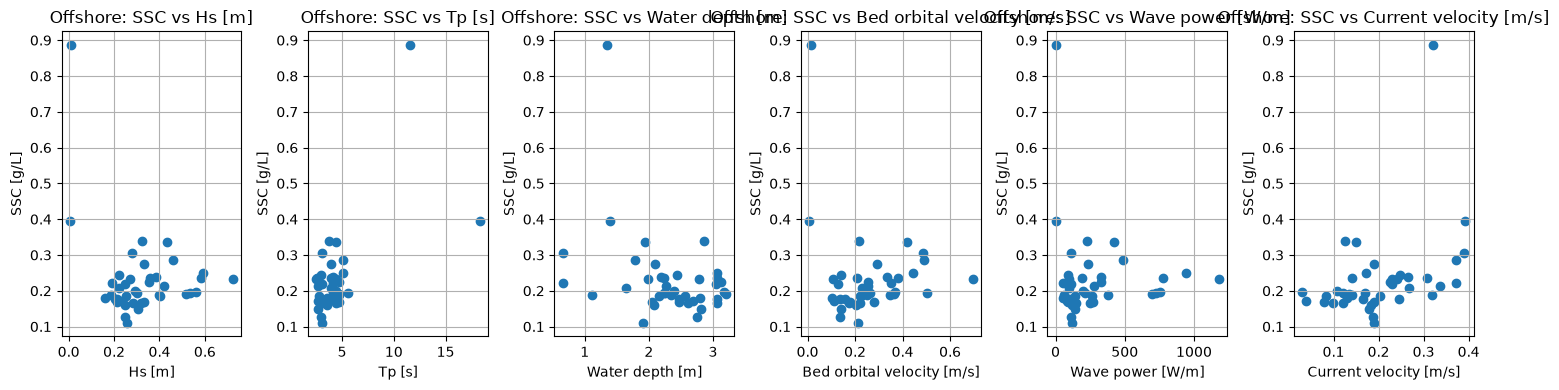

In [61]:
# Offshore SSC relationships

plot_ssc_relationships(
    off_ssc_valid,
    ["Hs", "Tp", "Depth", "U_bed", "P", "Current_velocity"],
    ["Hs [m]",
     "Tp [s]",
     "Water depth [m]",
     "Bed orbital velocity [m/s]",
     "Wave power [W/m]",
     "Current velocity [m/s]"],
    "Offshore"
)

# Buoy vs adcp check in correlation

Hs correlation: 0.941
Hs mean difference [m]: 0.021


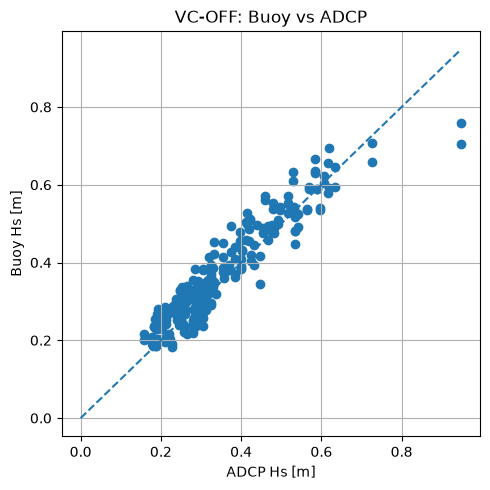

In [62]:
# Check agreement between the two offshore wave instruments

buoy_check = processed[2025]["buoy_wave"].loc[
    ~processed[2025]["buoy_wave"]["QA_outlier"],
    ["Date_time", "Hs", "Tp"]
].rename(columns={
    "Hs": "Hs_buoy",
    "Tp": "Tp_buoy"
})

adcp_check = processed[2025]["adcp_wave"].loc[
    ~processed[2025]["adcp_wave"]["QA_invalid"],
    ["Date_time", "Hs", "Tp"]
].rename(columns={
    "Hs": "Hs_adcp",
    "Tp": "Tp_adcp"
})

offshore_check = merge_nearest(
    buoy_check,
    adcp_check,
    tolerance="30min"
).dropna()


print("Hs correlation:",
      offshore_check["Hs_buoy"].corr(offshore_check["Hs_adcp"]).round(3))

print("Hs mean difference [m]:",
      (offshore_check["Hs_buoy"] - offshore_check["Hs_adcp"]).mean().round(3))


plt.figure(figsize=(5, 5))

plt.scatter(
    offshore_check["Hs_adcp"],
    offshore_check["Hs_buoy"]
)

limit = max(
    offshore_check["Hs_adcp"].max(),
    offshore_check["Hs_buoy"].max()
)

plt.plot([0, limit], [0, limit], "--")

plt.xlabel("ADCP Hs [m]")
plt.ylabel("Buoy Hs [m]")
plt.title("VC-OFF: Buoy vs ADCP")
plt.grid()

plt.tight_layout()
figures["buoy_vs_adcp_hs_2025"] = plt.gcf()
plt.show()

Buoy and ADCP agree well once the artefacts are flagged (r ≈ 0.94, buoy on average 0.02 m higher).

In [63]:
# Correlations

near_corr = near_2025_ssc[
    ["SSC", "Hs", "Tp", "Water_depth", "U_bed", "P"]
].corr()

off_corr = off_2025_ssc[
    ["SSC", "Hs", "Tp", "Depth", "U_bed", "P", "Current_velocity"]
].corr()


print("Nearshore")
display(near_corr.round(2))

print("Offshore")
display(off_corr.round(2))

Nearshore


,SSC,Hs,Tp,Water_depth,U_bed,P
SSC,1.00,0.14,0.06,0.29,0.41,0.41
Hs,0.14,1.00,0.38,0.81,1.00,0.96
Tp,0.06,0.38,1.00,0.78,0.03,-0.10
Water_depth,0.29,0.81,0.78,1.00,0.71,0.56
U_bed,0.41,1.00,0.03,0.71,1.00,0.96
P,0.41,0.96,-0.10,0.56,0.96,1.00


Offshore


,SSC,Hs,Tp,Depth,U_bed,P,Current_velocity
SSC,1.00,-0.47,0.70,-0.54,0.08,-0.22,0.38
Hs,-0.47,1.00,-0.43,0.47,0.25,0.91,-0.23
Tp,0.70,-0.43,1.00,-0.40,-0.19,-0.14,0.34
Depth,-0.54,0.47,-0.40,1.00,-0.45,0.39,-0.63
U_bed,0.08,0.25,-0.19,-0.45,1.00,0.19,0.05
P,-0.22,0.91,-0.14,0.39,0.19,1.00,-0.17
Current_velocity,0.38,-0.23,0.34,-0.63,0.05,-0.17,1.00


In [64]:
# SSC relationship summary, correlation also compared with Spearman

def relation_table(df, variables, location):

    results = []

    for var in variables:

        pair = df[["SSC", var]].dropna()

        results.append({
            "Location": location,
            "Variable": var,
            "N": len(pair),
            "Pearson": pair["SSC"].corr(pair[var]),
            "Spearman": pair["SSC"].corr(pair[var], method="spearman")
        })

    return pd.DataFrame(results)


ssc_relations = pd.concat([
    relation_table(
        near_ssc_valid,
        ["Hs", "Tp", "Water_depth", "U_bed", "P"],
        "Nearshore"
    ),

    relation_table(
        off_ssc_valid,
        ["Hs", "Tp", "Depth", "U_bed", "P", "Current_velocity"],
        "Offshore"
    )
], ignore_index=True)


display(ssc_relations.round(3))

,Location,Variable,N,Pearson,Spearman
0,Nearshore,Hs,12,0.431,0.501
1,Nearshore,Tp,12,0.134,0.329
2,Nearshore,Water_depth,12,0.352,0.364
3,Nearshore,U_bed,12,0.413,0.455
4,Nearshore,P,12,0.408,0.531
5,Offshore,Hs,40,-0.277,0.205
6,Offshore,Tp,40,0.613,0.305
7,Offshore,Depth,40,-0.353,-0.261
8,Offshore,U_bed,40,-0.148,0.294
9,Offshore,P,40,-0.084,0.141


In [65]:
# Determine rising/falling tide from water-depth change
# Assumption: positive depth change = rising tide, negative = falling tide.

near_tide = processed[2025]["water_depth"][
    ["Date_time", "Depth"]
].dropna().sort_values("Date_time").copy()

near_tide["Tide_stage"] = np.where(
    near_tide["Depth"].diff() >= 0,
    "Rising",
    "Falling"
)


off_tide = processed[2025]["adcp_wave"][
    ["Date_time", "Depth"]
].dropna().sort_values("Date_time").copy()

off_tide["Tide_stage"] = np.where(
    off_tide["Depth"].diff() >= 0,
    "Rising",
    "Falling"
)


near_ssc_valid = merge_nearest(
    near_ssc_valid,
    near_tide[["Date_time", "Tide_stage"]],
    tolerance="30min"
)

off_ssc_valid = merge_nearest(
    off_ssc_valid,
    off_tide[["Date_time", "Tide_stage"]],
    tolerance="1h"
)

In [66]:
# SSC during rising and falling tide

tidal_ssc = pd.concat([
    near_ssc_valid.assign(Location="Nearshore"),
    off_ssc_valid.assign(Location="Offshore")
])

tidal_ssc_summary = (
    tidal_ssc
    .groupby(["Location", "Tide_stage"])["SSC"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(tidal_ssc_summary.round(3))

count   mean  median    min    max
Location  Tide_stage                                    
Nearshore Falling         7  0.405   0.366  0.166  0.720
          Rising          5  0.461   0.651  0.141  0.681
Offshore  Falling        23  0.247   0.198  0.128  0.886
          Rising         17  0.208   0.196  0.111  0.336

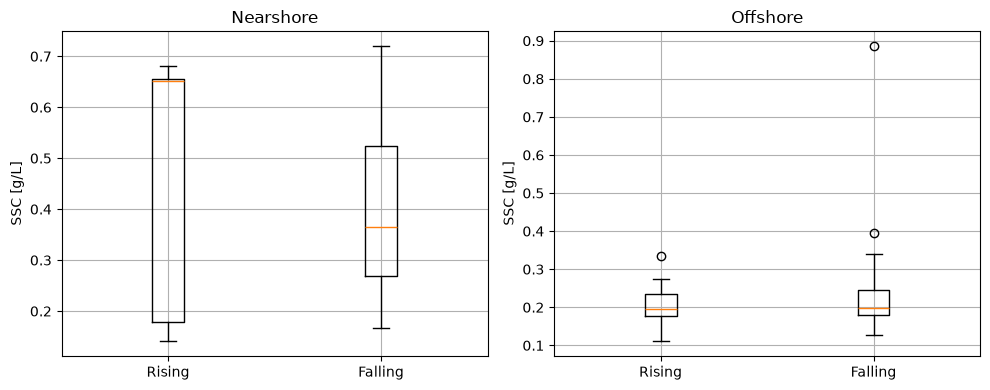

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (location, df) in zip(
    axes,
    [
        ("Nearshore", near_ssc_valid),
        ("Offshore", off_ssc_valid)
    ]
):

    rising = df.loc[df["Tide_stage"] == "Rising", "SSC"].dropna()
    falling = df.loc[df["Tide_stage"] == "Falling", "SSC"].dropna()

    ax.boxplot(
        [rising, falling],
        tick_labels=["Rising", "Falling"]
    )

    ax.set_title(location)
    ax.set_ylabel("SSC [g/L]")
    ax.grid()

plt.tight_layout()
figures["ssc_rising_falling"] = fig
plt.show()

## Raw data per sensor
All variables of each data file. Flagged records shown in orange (nothing removed). Figures saved to results.

In [ ]:
# Appendix: raw data per sensor: functions

COL_VALID, COL_FLAG = "#2a78d6", "#eb6834"

def plot_sensor(df, panels, flag_col=None, clip=None, out=None, width_cm=16, panel_cm=3.2):
    clip = clip or {}
    df = df.sort_values("Date_time")
    flag = df[flag_col].fillna(False).astype(bool) if flag_col else pd.Series(False, index=df.index)
    dense = len(df) > 400
    fig, axes = plt.subplots(len(panels), 1, sharex=True,
                             figsize=(width_cm / 2.54, panel_cm * len(panels) / 2.54 + 0.6),
                             squeeze=False)
    for ax, (col, label, kind) in zip(axes[:, 0], panels):
        t, y = df["Date_time"], df[col]
        top = clip.get(col, np.inf)
        over = y > top
        y_ok = y.where(~flag)                     
        if kind == "line":
            ax.plot(t, y_ok, "-", color=COL_VALID, lw=0.9, marker=None if dense else "o", ms=2)
        else:
            ax.plot(t, y_ok, "o", color=COL_VALID, ms=1.8 if dense else 2.5)
        show = flag & ~over
        ax.plot(t[show], y[show], "o", mfc="none", mec=COL_FLAG, ms=3.5, mew=0.9)
        if over.any():                            
            ax.set_ylim(top=top * 1.12)
            ax.plot(t[over], np.full(over.sum(), top * 1.05), "^", color=COL_FLAG, ms=4)
            groups = (t[over].diff() > pd.Timedelta("3h")).cumsum()
            for _, g in y[over].groupby(groups.values):
                ax.annotate(" / ".join(f"{v:.1f}" for v in g), (t[g.index[0]], top * 1.05),
                            xytext=(4, -2.5), textcoords="offset points", fontsize=6, color="#555")
        ax.set_ylabel(label, fontsize=7)
        ax.tick_params(labelsize=7)
        ax.grid(axis="y", color="#e4e4e2", lw=0.6)
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)
    handles = [plt.Line2D([], [], color=COL_VALID, marker="o", ms=2.5, lw=0.9, label="data")]
    if flag.any():
        handles += [plt.Line2D([], [], ls="none", marker="o", mfc="none", mec=COL_FLAG, ms=3.5, label="QA-flagged (kept)")]
    if any(c in clip for c, _, _ in panels):
        handles += [plt.Line2D([], [], ls="none", marker="^", color=COL_FLAG, ms=4, label="off scale (value shown)")]
    if len(handles) > 1:                         
        fig.legend(handles=handles, loc="upper center", ncol=len(handles), fontsize=6.5, frameon=False)
    axes[-1, 0].xaxis.set_major_locator(mdates.DayLocator())
    axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    axes[-1, 0].set_xlabel(f"Date ({df['Date_time'].dt.year.iloc[0]}, local time UTC+7)", fontsize=7)
    fig.align_ylabels()
    legend_space = 0.35 / (panel_cm * len(panels) / 2.54 + 0.6) if len(handles) > 1 else 0
    plt.tight_layout(h_pad=0.4, rect=(0, 0, 1, 1 - legend_space))
    return fig

In [69]:
# Appendix: raw data per sensor: run cell 
appendix_figures = {
    "A1_2025_VC-OFF_ADCP_wave": dict(
        df=processed[2025]["adcp_wave"], flag_col="QA_invalid",
        panels=[("Depth", "Depth above\nsensor [m]", "line"), ("Hs", "Hs [m]", "line"),
                ("Tp", "Tp [s]", "dot"), ("Direction", "Direction\n[° from N]", "dot"),
                ("HsSwell", "Hs swell [m]", "line"), ("TpSwell", "Tp swell [s]", "dot"),
                ("DpSwell", "Dir. swell\n[° from N]", "dot")]),
    "A2_2025_VC-OFF_ADCP_flow": dict(
        df=processed[2025]["adcp_flow"].merge(processed[2025]["adcp_wave"][["Date_time", "Depth"]], on="Date_time"),
        flag_col="QA_invalid",
        panels=[("Depth", "Depth above\nsensor [m]", "line"), ("Vel", "Depth-averaged\ncurrent [m/s]", "line"),
                ("Dir", "Dir [°]", "dot")]),
    "A3_2025_VC-OFF_buoy": dict(
        df=processed[2025]["buoy_wave"], flag_col="QA_outlier", clip={"Hs": 1.0, "H_max": 2.0},
        panels=[("Hs", "Hs [m]", "line"), ("H_max", "H$_{max}$ [m]", "line"),
                ("Tp", "Tp [s]", "dot"), ("Dir", "Direction\n[° from N]", "dot")]),
    "A4_2025_VC-NEAR_diver": dict(
        df=processed[2025]["water_depth"], flag_col=None, panel_cm=5,
        panels=[("Depth", "Water depth [m]", "line")]),
    "A5_2025_VC-NEAR_TWR": dict(
        df=processed[2025]["twr_wave"], flag_col="QA_invalid",
        panels=[("Depth", "Depth (raw) [m]", "line"), ("Hs", "Hs [m]", "line"),
                ("H_max", "H$_{max}$ [m]", "line"), ("Tp", "Tp [s]", "dot"), ("T_max", "T$_{max}$ [s]", "dot")]),
    "A6_2026_VC-TWR_TWR": dict(
        df=near_2026, flag_col="QA_invalid",
        panels=[("Depth", "Depth (raw) [m]", "line"), ("Hs", "Hs [m]", "line"),
                ("H_max", "H$_{max}$ [m]", "line"), ("H_mean", "H$_{mean}$ [m]", "line"),
                ("H_10", "H$_{1/10}$ [m]", "line"), ("Wave_energy", "Wave energy\n[J/m²]", "line")]),
    "A7_2026_VC-BUOY-S_buoy": dict(
        df=processed[2026]["buoy_wave"], flag_col="QA_outlier", clip={"Hs": 1.4},
        panels=[("Hs", "Hs [m]", "line"), ("H_max", "H$_{max}$ [m]", "line"),
                ("Tp", "Tp [s]", "dot"), ("Dir", "Direction\n[° from N]", "dot")]),
}

for name, s in appendix_figures.items():
    fig = plot_sensor(s["df"], s["panels"], flag_col=s["flag_col"], clip=s.get("clip"),
                      panel_cm=s.get("panel_cm", 3.2))
    figures[name] = fig
    plt.close(fig)   # raw data: not shown in the notebook, only saved when SAVE = True

# Save figures
Only figures and wave transformtion tables are saved to `results`. No data or tables are written (the data are restricted).

In [70]:
# Save figures and tables (only when SAVE = True)
if SAVE:
    fig_dir.mkdir(parents=True, exist_ok=True)
    table_dir.mkdir(parents=True, exist_ok=True)
    for name, fig in figures.items():
        fig.savefig(fig_dir / f"{name}.png", dpi=300, bbox_inches="tight")
    for name, table in tables.items():
        table.to_csv(table_dir / f"{name}.csv")